In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D

from plot_style import apply

FIG = Path("figs")
DATA_PATH = FIG / "data" / "basin_boundary_two_r.npz"
OUTPUT = FIG / "Fig7.pdf"

apply()

BLUE = "#9ecae1"
RED = "#ef8a83"
BOUNDARY = "#202020"
CORE = "#d9d9d9"

with np.load(DATA_PATH) as archive:
    data = {name: archive[name] for name in archive.files}

r_values = data["r_values"]
grid_axis = data["axis"]
partitions = data["partitions"]

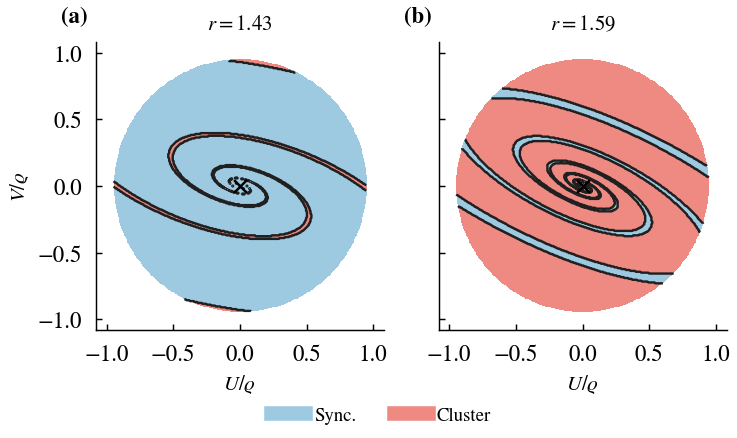

In [2]:
cmap = ListedColormap([CORE, BLUE, RED])
norm = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], cmap.N)

DISPLAY_RADIUS = 0.95
U_grid, V_grid = np.meshgrid(grid_axis, grid_axis, indexing="xy")
display_disk = np.hypot(U_grid, V_grid) <= DISPLAY_RADIUS

fig, ax = plt.subplots(1, 2, figsize=(5, 3), constrained_layout=False)
fig.subplots_adjust(left=0.10, right=0.98, bottom=0.24, top=0.88, wspace=0.08)

for panel, (axis, r, partition) in enumerate(zip(ax, r_values, partitions)):
    masked_partition = np.ma.masked_where(
        (partition == -2) | (~display_disk),
        partition,
    )
    axis.imshow(
        masked_partition,
        origin="lower",
        extent=[-1, 1, -1, 1],
        interpolation="nearest",
        cmap=cmap,
        norm=norm,
        zorder=0,
    )

    cluster_mask = np.ma.masked_where(
        (partition < 0) | (~display_disk),
        partition == 1,
    )
    axis.contour(
        grid_axis,
        grid_axis,
        cluster_mask.astype(float),
        levels=[0.5],
        colors=[BOUNDARY],
        linewidths=1.15,
        zorder=4,
    )

    axis.scatter([0], [0], marker="x", s=38, color="black", linewidths=1.2, zorder=8)

    axis.set(
        xlim=(-1.08, 1.08),
        ylim=(-1.08, 1.08),
        aspect="equal",
        xlabel=r"$U/\varrho$",
        title=fr"$r={r:.2f}$",
    )

    if panel == 0:
        axis.set_ylabel(r"$V/\varrho$")
    else:
        axis.set_yticklabels([])

    axis.set_xticks([-1, -0.5, 0, 0.5, 1])
    axis.set_yticks([-1, -0.5, 0, 0.5, 1])

    axis.text(
        -0.12, 1.05,
        f"({chr(97 + panel)})",
        transform=axis.transAxes,
        ha="left",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        clip_on=False,
    )
    axis.tick_params(direction="in", pad=6.5, labelsize=11)

fig.legend(
    handles=[
        Line2D([0], [0], color=BLUE, lw=7, label="Sync."),
        Line2D([0], [0], color=RED, lw=7, label="Cluster"),
    ],
    bbox_to_anchor=(0.5, 0),
    loc="outside lower center",
    ncol=3,
    frameon=False,
    fontsize=9,
)

fig.savefig(OUTPUT, bbox_inches="tight")
plt.show()